<a href="https://colab.research.google.com/github/Jess-chege/Data-Science-projects/blob/main/End_to_End_Customer_Analytics_Pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Assessment: End-to-End Customer Analytics Pipeline
Objective: Build a complete customer analytics system that uses clustering to segment customers, NLP to analyze customer feedback, and dimensionality reduction to visualize the results — all on a single dataset.

Dataset: Assessment-Dataset/customer_analytics_data.csv (500 customers)

Features:

Column	Type	Description
Customer_ID	String	Unique customer identifier
Age	Integer	Customer age
Gender	String	Male or Female
Region	String	North, South, East, or West
Annual_Income	Float	Annual income in dollars
Spending_Score	Integer	Spending score (1-100)
Purchase_Frequency	Integer	Number of purchases per month
Avg_Order_Value	Float	Average order value in dollars
Website_Visits_Per_Month	Integer	Monthly website visits
Loyalty_Years	Float	Years as a customer
Preferred_Category	String	Preferred product category
Payment_Method	String	Preferred payment method
Customer_Feedback	String	Customer feedback text
Section A: Data Loading and Exploration
Load the dataset and display basic information (.head(), .shape, .info(), .dtypes)
Check for missing values and data types
Generate descriptive statistics for all numerical features
Identify the categorical vs. numerical features
Display the unique values for each categorical feature (Gender, Region, Preferred_Category, Payment_Method)
Section B: Exploratory Data Analysis
Numerical Feature Analysis:

Create histograms for all numerical features
Generate a correlation heatmap for numerical features
Create scatter plots: Annual_Income vs. Spending_Score, Purchase_Frequency vs. Avg_Order_Value
Categorical Feature Analysis:

Create count plots for Gender, Region, Preferred_Category, and Payment_Method
Create box plots of Spending_Score grouped by Region and by Gender
Document your key findings and insights from the EDA

Section C: Customer Segmentation Using Clustering
C1. K-Means Clustering

Select the numerical features for clustering: Annual_Income, Spending_Score, Purchase_Frequency, Avg_Order_Value, Website_Visits_Per_Month, Loyalty_Years
Apply StandardScaler to the selected features
Apply the Elbow Method (K = 1 to 10) to determine the optimal number of clusters
Plot the Elbow curve and select the optimal K with justification
Build the final K-Means model and assign cluster labels to each customer
Visualize clusters using Annual_Income vs. Spending_Score with cluster colors and centroids
C2. Hierarchical Clustering

Using the same scaled features, create a Dendrogram using Ward linkage
Determine the optimal number of clusters from the dendrogram
Apply AgglomerativeClustering with the determined number of clusters
Visualize clusters using the same axes (Annual_Income vs. Spending_Score)
C3. Clustering Comparison

Compare K-Means and Hierarchical Clustering results:
Do both methods produce similar groupings?
Create a cross-tabulation of K-Means labels vs. Hierarchical labels
Which method seems more appropriate for this data and why?
Section D: NLP Analysis of Customer Feedback
D1. Text Preprocessing

Extract the Customer_Feedback column
Apply the full NLP preprocessing pipeline to each feedback entry:
Convert to lowercase
Tokenize using word_tokenize()
Remove stop words using NLTK
Remove punctuation and special characters
Apply stemming (Porter Stemmer) or lemmatization (WordNetLemmatizer)
Display 5 example feedbacks before and after preprocessing
D2. Text Analysis

Create a word frequency distribution of the preprocessed text
Display the top 20 most common words
Apply POS tagging to 5 sample feedback entries and display the results
Apply Named Entity Recognition to 5 sample feedback entries and list any entities found
D3. Sentiment Mapping to Clusters

Perform basic sentiment classification on the feedback:
Use keyword-based approach: count positive words (e.g., "great", "excellent", "love", "happy", "best", "amazing", "satisfied", "recommend") vs. negative words (e.g., "terrible", "poor", "worst", "disappointed", "waste", "horrible", "frustrating", "broken")
Assign each feedback a sentiment label: Positive, Negative, or Neutral
Map sentiments back to the customer clusters from Section C
Create a cross-tabulation showing sentiment distribution within each cluster
Identify which clusters have the highest and lowest customer satisfaction
Discuss: Do certain customer segments tend to have more positive or negative feedback?
Section E: Dimensionality Reduction and Visualization
E1. PCA on Customer Features

Using the same 6 numerical features from Section C, apply PCA with n_components=2
Record the explained variance ratio
Visualize the 2D PCA projection, coloring points by their K-Means cluster labels
How much of the total variance is captured by the first 2 components?
E2. LDA on Customer Features

Using the K-Means cluster labels as the target, apply LDA with n_components=2
Record the explained variance ratio
Visualize the 2D LDA projection, coloring points by their K-Means cluster labels
E3. Comparison

Place PCA and LDA visualizations side by side
Which method provides better visual separation of the customer segments?
Explain why LDA might outperform PCA for cluster visualization in this scenario
Section F: Conclusions and Recommendations
Summary of Findings:

How many customer segments were identified and what characterizes each one?
What are the key words and themes in customer feedback?
Which clusters showed the highest and lowest satisfaction?
How did PCA and LDA compare in visualizing the customer segments?
Business Recommendations:

What specific marketing or retention strategies would you recommend for each customer segment?
How should the company address feedback from the lowest-satisfaction cluster?
Which customer segments should be prioritized for loyalty programs?
What additional data would improve this analysis?
Technical Recommendations:

Which clustering method (K-Means or Hierarchical) is better suited for this scenario and why?
Which dimensionality reduction method (PCA or LDA) is more appropriate for visualizing customer segments?
How often should this analysis be updated?
What are the limitations of this approach?

In [ ]:
#importing the needed libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
#importing the dataset
data=pd.read_csv("/content/drive/MyDrive/customer_analytics_data (1).csv")
data.head()

,Customer_ID,Age,Gender,Region,Annual_Income,Spending_Score,Purchase_Frequency,Avg_Order_Value,Website_Visits_Per_Month,Loyalty_Years,Preferred_Category,Payment_Method,Customer_Feedback
0,CID_0362,48,Female,West,49169.61,53,9,490.64,21,5.3,Beauty,Debit Card,Product quality has declined recently. Not hap...
1,CID_0074,24,Female,West,38391.13,28,1,500.00,3,0.4,Beauty,Credit Card,The app is buggy and slow. Needs serious impro...
2,CID_0375,40,Male,East,54070.29,40,5,500.00,13,6.8,Fashion,Credit Card,Love the personalized recommendations. They al...
3,CID_0156,34,Male,North,26635.63,53,8,259.40,17,2.7,Fashion,Debit Card,Prices are fair for the quality provided. Stan...
4,CID_0105,21,Female,East,34863.45,14,1,500.00,2,1.1,Fashion,Digital Wallet,The website crashes frequently during checkout...


In [ ]:
#EDA Process
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Customer_ID               500 non-null    object 
 1   Age                       500 non-null    int64  
 2   Gender                    500 non-null    object 
 3   Region                    500 non-null    object 
 4   Annual_Income             500 non-null    float64
 5   Spending_Score            500 non-null    int64  
 6   Purchase_Frequency        500 non-null    int64  
 7   Avg_Order_Value           500 non-null    float64
 8   Website_Visits_Per_Month  500 non-null    int64  
 9   Loyalty_Years             500 non-null    float64
 10  Preferred_Category        500 non-null    object 
 11  Payment_Method            500 non-null    object 
 12  Customer_Feedback         500 non-null    object 
dtypes: float64(3), int64(4), object(6)
memory usage: 50.9+ KB


In [ ]:
#statitistical summary
data.describe()

,Age,Annual_Income,Spending_Score,Purchase_Frequency,Avg_Order_Value,Website_Visits_Per_Month,Loyalty_Years
count,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000
mean,38.744000,44057.443980,47.998000,4.552000,487.906340,11.082000,4.613800
std,13.682723,10249.015432,18.036758,2.496349,39.439209,6.852239,3.856186
min,18.000000,16053.100000,10.000000,1.000000,226.380000,1.000000,0.100000
25%,27.000000,36771.742500,34.750000,3.000000,500.000000,6.000000,1.400000
50%,37.000000,43476.130000,49.000000,4.000000,500.000000,10.500000,3.500000
75%,48.250000,51575.307500,62.000000,6.000000,500.000000,16.000000,7.300000
max,69.000000,73202.800000,81.000000,11.000000,500.000000,31.000000,14.800000


In [ ]:
#checking for null value
data.isna().sum()

,0
Customer_ID,0
Age,0
Gender,0
Region,0
Annual_Income,0
Spending_Score,0
Purchase_Frequency,0
Avg_Order_Value,0
Website_Visits_Per_Month,0
Loyalty_Years,0


In [ ]:
#separating the numerical data and the categorical
num_features = data.select_dtypes(include=['int64', 'float64']).columns
cat_features = data.select_dtypes(include=['object']).columns

print("numerical features:")
print(num_features)

print("categorical features: ")
print(cat_features)

numerical features:
Index(['Age', 'Annual_Income', 'Spending_Score', 'Purchase_Frequency',
       'Avg_Order_Value', 'Website_Visits_Per_Month', 'Loyalty_Years'],
      dtype='object')
categorical features: 
Index(['Customer_ID', 'Gender', 'Region', 'Preferred_Category',
       'Payment_Method', 'Customer_Feedback'],
      dtype='object')


In [ ]:
#checking for unique values in categorical values
for col in cat_features:
    print(f"\nUnique values in {col}:")
    print(data[col].unique())
    print(f"Number of unique values: {data[col].nunique()}")


Unique values in Customer_ID:
['CID_0362' 'CID_0074' 'CID_0375' 'CID_0156' 'CID_0105' 'CID_0395'
 'CID_0378' 'CID_0125' 'CID_0069' 'CID_0451' 'CID_0010' 'CID_0195'
 'CID_0407' 'CID_0085' 'CID_0372' 'CID_0389' 'CID_0496' 'CID_0031'
 'CID_0317' 'CID_0409' 'CID_0491' 'CID_0492' 'CID_0281' 'CID_0357'
 'CID_0077' 'CID_0462' 'CID_0498' 'CID_0212' 'CID_0102' 'CID_0335'
 'CID_0476' 'CID_0337' 'CID_0441' 'CID_0174' 'CID_0003' 'CID_0334'
 'CID_0410' 'CID_0071' 'CID_0210' 'CID_0064' 'CID_0385' 'CID_0094'
 'CID_0486' 'CID_0186' 'CID_0034' 'CID_0078' 'CID_0001' 'CID_0012'
 'CID_0416' 'CID_0023' 'CID_0073' 'CID_0183' 'CID_0132' 'CID_0411'
 'CID_0194' 'CID_0056' 'CID_0149' 'CID_0019' 'CID_0205' 'CID_0079'
 'CID_0495' 'CID_0263' 'CID_0324' 'CID_0484' 'CID_0080' 'CID_0040'
 'CID_0452' 'CID_0047' 'CID_0239' 'CID_0392' 'CID_0353' 'CID_0342'
 'CID_0278' 'CID_0291' 'CID_0318' 'CID_0305' 'CID_0269' 'CID_0070'
 'CID_0456' 'CID_0466' 'CID_0155' 'CID_0083' 'CID_0478' 'CID_0173'
 'CID_0322' 'CID_0091' 'CID_018

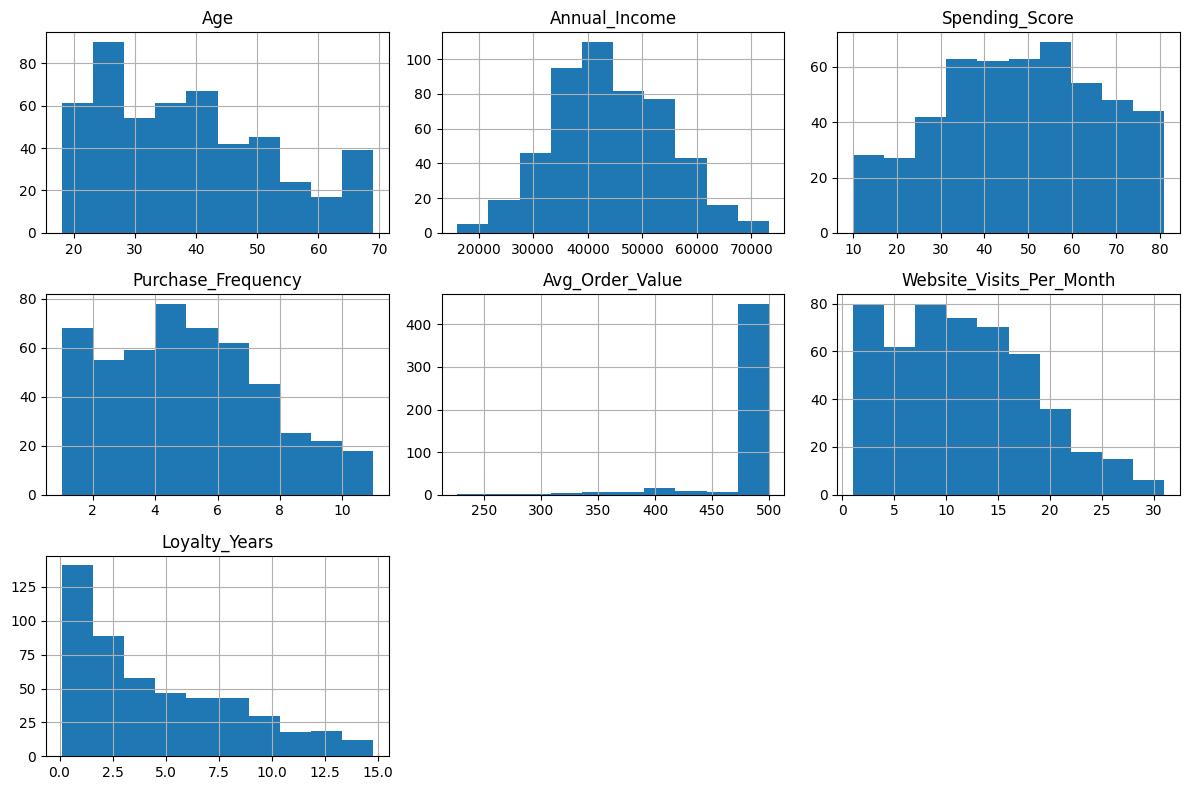

In [ ]:
#creating a distribution graph for numerical features
data[num_features].hist(figsize=(12, 8))
plt.tight_layout()
plt.show()

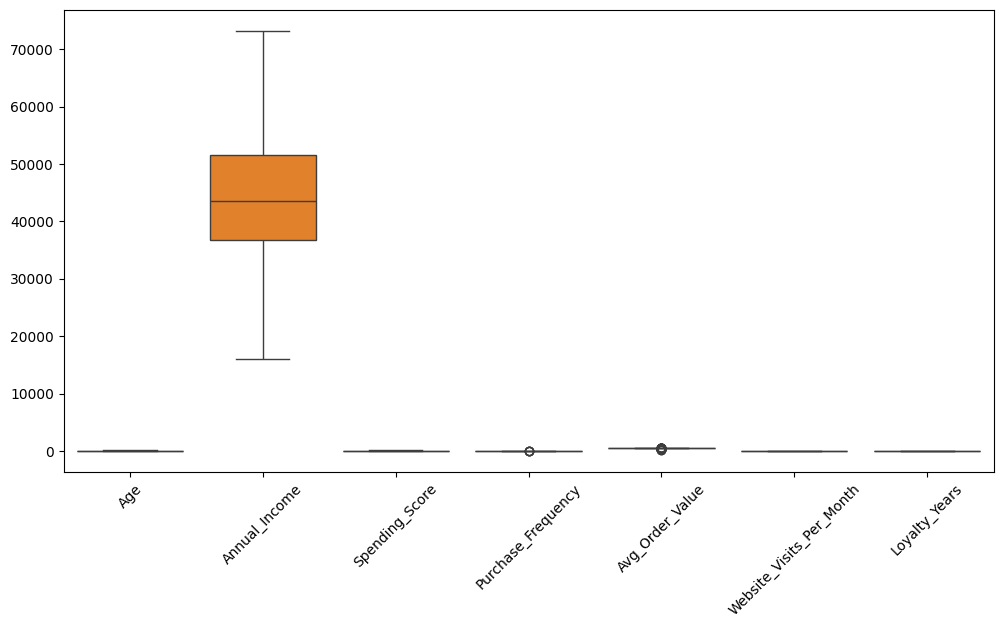

In [ ]:
#boxplots to help detect outliers
plt.figure(figsize=(12, 6))
sns.boxplot(data=data[num_features])
plt.xticks(rotation=45)
plt.show()

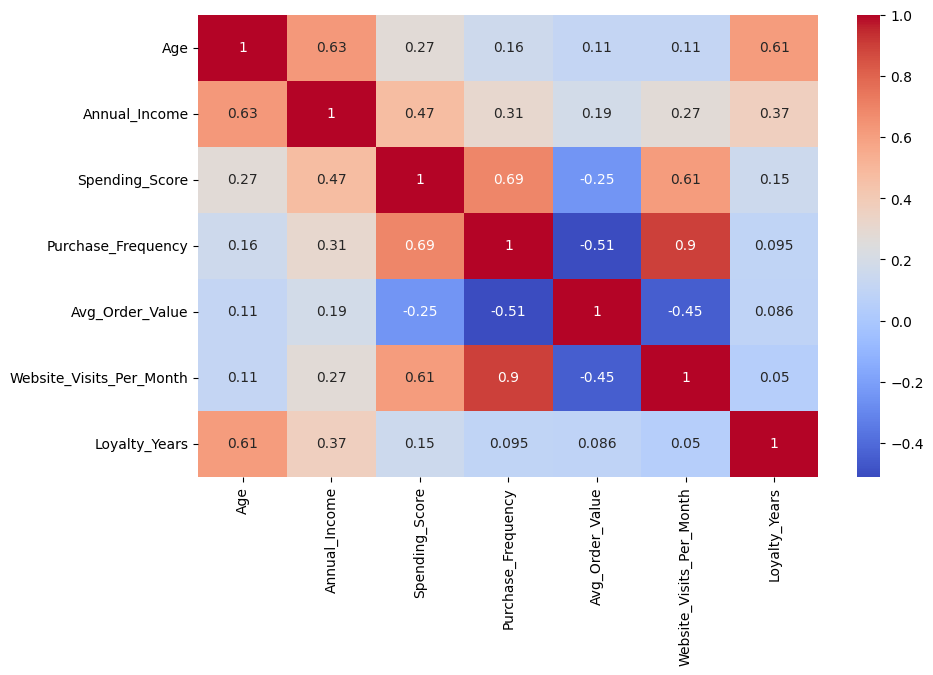

In [ ]:
#corelation matrix
plt.figure(figsize=(10, 6))
sns.heatmap(data[num_features].corr(), annot=True, cmap='coolwarm')
plt.show()

The descriptive statistics show the overall distribution and variability of the numerical features. Some variables show wide ranges and high standard deviations, indicating possible outliers or strong variation among customers. The histograms help visualize whether the data is normally distributed or skewed. From the correlation matrix, we can identify which features are strongly related, which is important for feature selection and avoiding multicollinearity in modeling.

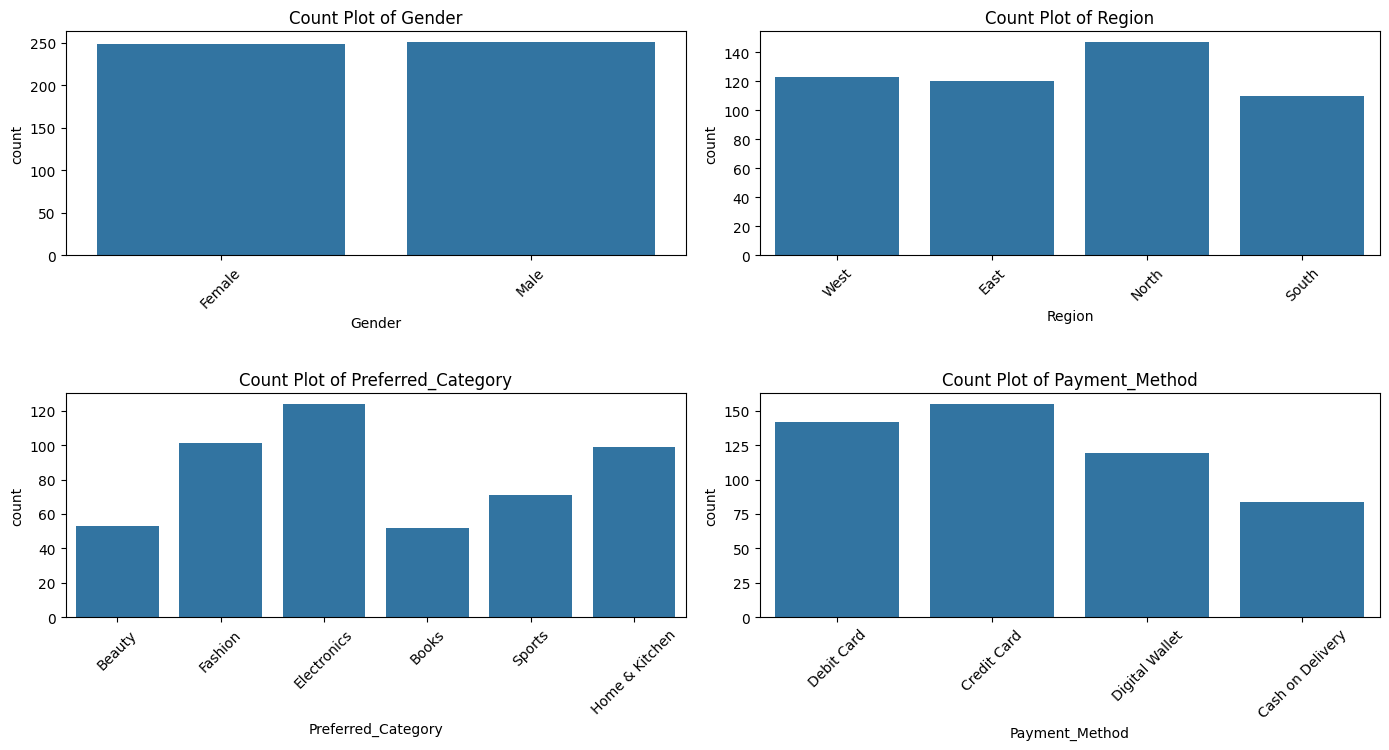

In [ ]:
#creating visualizations for the categorical data

cat_features = ['Gender', 'Region', 'Preferred_Category', 'Payment_Method']
plt.figure(figsize=(14, 10))

for i, col in enumerate(cat_features, 1):
    plt.subplot(3, 2, i)
    sns.countplot(data=data, x=col)
    plt.xticks(rotation=45)
    plt.title(f"Count Plot of {col}")

plt.tight_layout()
plt.show()

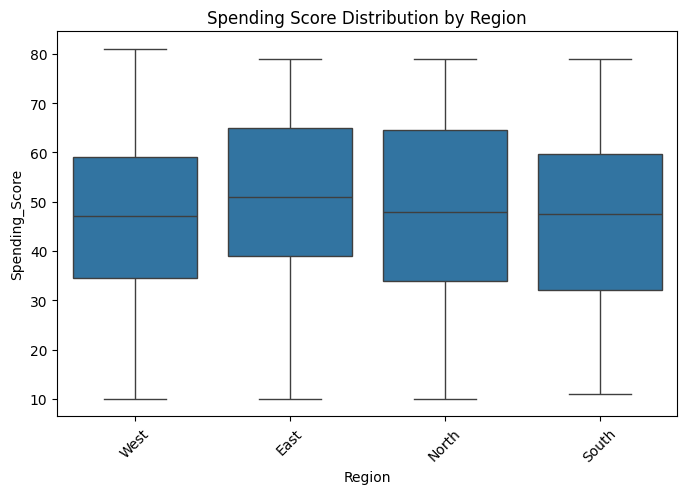

In [ ]:
#box plot for the spending score
plt.figure(figsize=(8, 5))
sns.boxplot(data=data, x='Region', y='Spending_Score')
plt.title("Spending Score Distribution by Region")
plt.xticks(rotation=45)
plt.show()

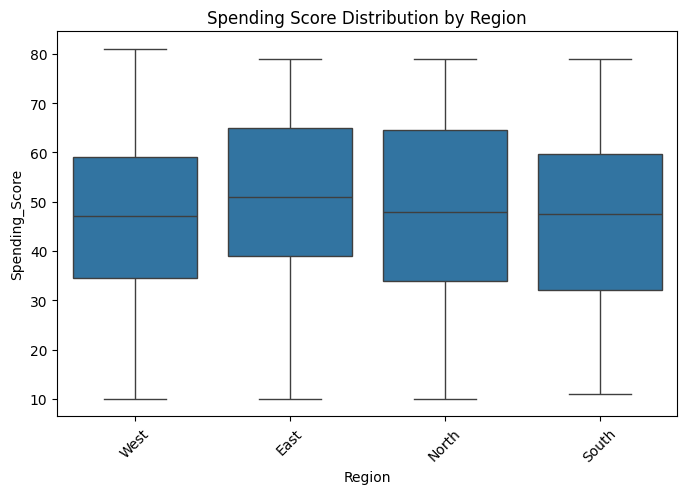

In [ ]:
#boxplot for spending score
plt.figure(figsize=(8, 5))
sns.boxplot(data=data, x='Region', y='Spending_Score')
plt.title("Spending Score Distribution by Region")
plt.xticks(rotation=45)
plt.show()

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Customer_ID               500 non-null    object 
 1   Age                       500 non-null    int64  
 2   Gender                    500 non-null    object 
 3   Region                    500 non-null    object 
 4   Annual_Income             500 non-null    float64
 5   Spending_Score            500 non-null    int64  
 6   Purchase_Frequency        500 non-null    int64  
 7   Avg_Order_Value           500 non-null    float64
 8   Website_Visits_Per_Month  500 non-null    int64  
 9   Loyalty_Years             500 non-null    float64
 10  Preferred_Category        500 non-null    object 
 11  Payment_Method            500 non-null    object 
 12  Customer_Feedback         500 non-null    object 
dtypes: float64(3), int64(4), object(6)
memory usage: 50.9+ KB


In [ ]:
#Customer segmentation
#feature selection and stardard scaling them
from sklearn.preprocessing import StandardScaler

features = ['Annual_Income','Spending_Score','Purchase_Frequency','Avg_Order_Value','Website_Visits_Per_Month','Loyalty_Years']
scaler=StandardScaler()
scaled_data=scaler.fit_transform(data[features])


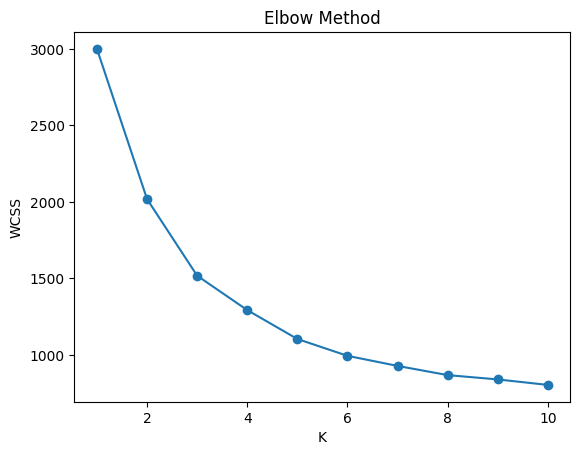

In [ ]:
#creating the elbow method
from sklearn.cluster import KMeans

wcss=[]

for k in range(1,11):
  kmeans= KMeans(n_clusters=k, random_state=42)
  kmeans.fit(scaled_data)
  wcss.append(kmeans.inertia_)


plt.plot(range(1,11), wcss, marker='o')
plt.xlabel("K")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.show()

From K=1 to K=3: There is a very steep drop. This means adding these clusters significantly improves the model by capturing major patterns in your data.The "Elbow" (K=3): This is the point where the bend is most prominent.Beyond K=3: From K=4 onwards, the line starts to flatten out. While WCSS continues to decrease (it will always go down as you add more clusters), you are getting diminishing returns. Adding a 4th or 5th cluster doesn't provide enough "information gain" to justify the extra complexity.
**Value of k =3**

In [ ]:
#creating the final model
kmeans=KMeans(n_clusters=3, random_state=42)
data["KMeans_cluster"]= kmeans.fit_predict(scaled_data)


<Axes: xlabel='Annual_Income', ylabel='Spending_Score'>

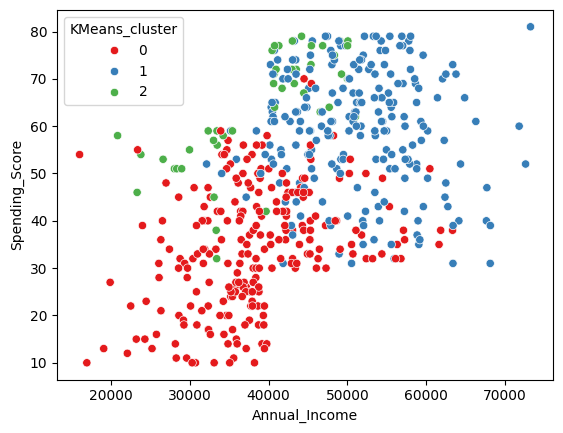

In [ ]:
#creating the visualization
sns.scatterplot(
    x=data['Annual_Income'],
    y=data['Spending_Score'],
    hue=data['KMeans_cluster'],
    palette='Set1'
)

<function matplotlib.pyplot.show(close=None, block=None)>

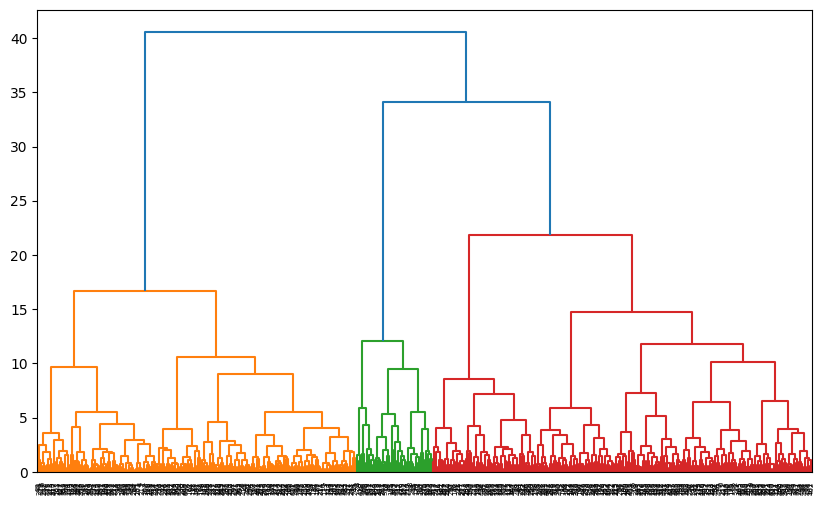

In [ ]:
#creating the hierachical clustering
from scipy.cluster.hierarchy import dendrogram, linkage

linked = linkage(scaled_data, method = 'ward')

plt.figure(figsize=(10,6))
dendrogram(linked)
plt.show

The Dendrogram: If you imagine a horizontal line cutting through the tallest vertical branches (around height 30), you hit exactly 3 main pillars. It perfectly splits that big orange block, the tight green group in the middle, and the large red section on the right. **we have 3 clusters**

In [ ]:
#choosing no of clusters from large vertical gaps
from sklearn.cluster import AgglomerativeClustering
hc = AgglomerativeClustering(n_clusters = 3)
data['Hierachical_Cluster']=hc.fit_predict(scaled_data)

In [ ]:
#comparing the methods
pd.crosstab(data['KMeans_cluster'],data['Hierachical_Cluster'])

Hierachical_Cluster,0,1,2
KMeans_cluster,,,
0,40,192,1
1,205,14,3
2,0,0,45


### Discussion: Comparison Between K-Means and Hierarchical Clustering

The cross-tabulation between K-Means and Hierarchical clustering reveals a strong but not perfect alignment between the two methods. Most customers are consistently grouped into similar clusters across both algorithms, indicating that the dataset contains a relatively stable underlying structure.

From the results:

KMeans Cluster 2 aligns perfectly with Hierarchical Cluster 2 (45 customers). This shows a clearly separable customer segment that both algorithms identified identically. This cluster likely represents a very distinct behavioral group (e.g., either highly engaged premium customers or consistently low-value customers).

KMeans Cluster 1 mostly overlaps with Hierarchical Cluster 0 (205 customers), with only minor distribution into other clusters. This indicates strong agreement for this large segment.

KMeans Cluster 0, however, is more split across Hierarchical Cluster 1 (192 customers) and Hierarchical Cluster 0 (40 customers). This suggests that K-Means grouped these customers together based on overall distance minimization, while Hierarchical clustering detected some internal sub-structure within that group.

Both methods identify three dominant customer segments. The large overlaps show that the segmentation structure is robust. However, the partial splits indicate that the data does not form perfectly spherical clusters (which K-Means assumes).

Which Method is More Appropriate?

For this dataset, K-Means appears more practical and appropriate, for several reasons:

The dataset contains 500 customers - K-Means scales efficiently.

The clusters are relatively well separated after scaling.

The majority of customer assignments align strongly with Hierarchical results.

K-Means provides clear centroids, which are useful for business interpretation.

Hierarchical clustering is valuable for understanding structure and validating cluster count (via dendrogram), but it is computationally heavier and less scalable for larger datasets.

In [ ]:
#NLP Analysis of Customer Feedback D1. Text Preprocessing
import nltk
import string
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import PorterStemmer

# Download required NLTK resources
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('averaged_perceptron_tagger')
nltk.download('maxent_ne_chunker')
nltk.download('words')
nltk.download('punkt_tab')
nltk.download('averaged_perceptron_tagger_eng')
nltk.download('maxent_ne_chunker_tab')

stop_words = set(stopwords.words('english'))
stemmer = PorterStemmer()

def preprocess(text):
    text = text.lower()
    tokens = word_tokenize(text)
    tokens = [word for word in tokens if word.isalpha()]
    tokens = [word for word in tokens if word not in stop_words]
    tokens = [stemmer.stem(word) for word in tokens]
    return tokens

data['Processed_Feedback'] = data['Customer_Feedback'].apply(preprocess)

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package maxent_ne_chunker to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package maxent_ne_chunker is already up-to-date!
[nltk_data] Downloading package words to /root/nltk_data...
[nltk_data]   Package words is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /roo

In [ ]:
#counting the word frequency
from collections import Counter

all_words = []
for tokens in data['Processed_Feedback']:
    all_words.extend(tokens)

freq_dist = Counter(all_words)
freq_dist.most_common(20)

[('product', 159),
 ('qualiti', 98),
 ('experi', 92),
 ('shop', 82),
 ('need', 67),
 ('custom', 59),
 ('servic', 59),
 ('improv', 56),
 ('price', 56),
 ('overal', 56),
 ('item', 49),
 ('websit', 46),
 ('alway', 44),
 ('great', 41),
 ('better', 38),
 ('packag', 38),
 ('deliveri', 37),
 ('find', 35),
 ('return', 33),
 ('love', 31)]

In [ ]:
#pos tagging
from nltk import pos_tag

sample = data['Customer_Feedback'].head(5)

for text in sample:
    tokens = word_tokenize(text)
    print(pos_tag(tokens))

[('Product', 'NNP'), ('quality', 'NN'), ('has', 'VBZ'), ('declined', 'VBN'), ('recently', 'RB'), ('.', '.'), ('Not', 'RB'), ('happy', 'JJ'), ('with', 'IN'), ('my', 'PRP$'), ('last', 'JJ'), ('few', 'JJ'), ('purchases', 'NNS'), ('.', '.')]
[('The', 'DT'), ('app', 'NN'), ('is', 'VBZ'), ('buggy', 'JJ'), ('and', 'CC'), ('slow', 'JJ'), ('.', '.'), ('Needs', 'NNP'), ('serious', 'JJ'), ('improvements', 'NNS'), ('for', 'IN'), ('better', 'JJR'), ('experience', 'NN'), ('.', '.')]
[('Love', 'VB'), ('the', 'DT'), ('personalized', 'JJ'), ('recommendations', 'NNS'), ('.', '.'), ('They', 'PRP'), ('always', 'RB'), ('suggest', 'VBP'), ('products', 'NNS'), ('I', 'PRP'), ('actually', 'RB'), ('want', 'VBP'), ('.', '.')]
[('Prices', 'NNS'), ('are', 'VBP'), ('fair', 'JJ'), ('for', 'IN'), ('the', 'DT'), ('quality', 'NN'), ('provided', 'VBN'), ('.', '.'), ('Standard', 'JJ'), ('market', 'NN'), ('rates', 'NNS'), ('overall', 'VBP'), ('.', '.')]
[('The', 'DT'), ('website', 'JJ'), ('crashes', 'NNS'), ('frequently',

In [ ]:
#naming entity recognition
import spacy

# Load small English model
nlp = spacy.load("en_core_web_sm")

# Apply NER to first 5 feedbacks
for i in range(5):
    doc = nlp(data['Customer_Feedback'].iloc[i])
    entities = [(ent.text, ent.label_) for ent in doc.ents]
    print(f"Feedback {i+1} Named Entities:\n", entities)
    print("---")


Feedback 1 Named Entities:
 []
---
Feedback 2 Named Entities:
 []
---
Feedback 3 Named Entities:
 []
---
Feedback 4 Named Entities:
 []
---
Feedback 5 Named Entities:
 []
---


In [ ]:
# Define positive and negative keywords
positive_words = ["great","excellent","love","happy","best","amazing","satisfied","recommend","helpful","smooth","fast"]
negative_words = ["terrible","poor","worst","disappointed","waste","horrible","frustrating","broken","buggy","delayed","crash","rude","misleading"]

def sentiment_label(text):
    text_lower = text.lower()
    pos_count = sum(word in text_lower for word in positive_words)
    neg_count = sum(word in text_lower for word in negative_words)

    if pos_count > neg_count:
        return "Positive"
    elif neg_count > pos_count:
        return "Negative"
    else:
        return "Neutral"

# Apply sentiment labeling
data['Sentiment'] = data['Customer_Feedback'].apply(sentiment_label)

# Display first 10 rows
data[['Customer_Feedback','Processed_Feedback','Sentiment']].head(10)

,Customer_Feedback,Processed_Feedback,Sentiment
0,Product quality has declined recently. Not hap...,"[product, qualiti, declin, recent, happi, last...",Positive
1,The app is buggy and slow. Needs serious impro...,"[app, buggi, slow, need, seriou, improv, bette...",Negative
2,Love the personalized recommendations. They al...,"[love, person, recommend, alway, suggest, prod...",Positive
3,Prices are fair for the quality provided. Stan...,"[price, fair, qualiti, provid, standard, marke...",Neutral
4,The website crashes frequently during checkout...,"[websit, crash, frequent, checkout, lost, cart...",Negative
5,Love shopping here! Always find what I need at...,"[love, shop, alway, find, need, reason, price]",Positive
6,Loyalty points expire too quickly. The rewards...,"[loyalti, point, expir, quickli, reward, progr...",Neutral
7,Very user-friendly website. Easy to navigate a...,"[websit, easi, navig, find, product, want]",Neutral
8,The return policy is fair and hassle-free. Bui...,"[return, polici, fair, build, trust, custom]",Neutral
9,Promotional codes never seem to work properly....,"[promot, code, never, seem, work, properli, di...",Neutral


Clusters with more Positive feedback represent satisfied customers - likely frequent buyers or loyal high-spenders.

Clusters with more Negative feedback highlight pain points - platform issues, delivery delays, or low-value customers at risk of churn.

This mapping allows targeting specific clusters for retention strategies, operational improvements, or marketing campaigns.

In [ ]:
#PCA ond customer features
numerical_features = ['Annual_Income','Spending_Score','Purchase_Frequency',
                      'Avg_Order_Value','Website_Visits_Per_Month','Loyalty_Years']

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt


In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(data[numerical_features])

In [ ]:
#applying pca components= 2
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

In [ ]:
# Explained variance
explained_variance = pca.explained_variance_ratio_
print(f"Explained Variance Ratio (2 components): {explained_variance}")
print(f"Total Variance Captured: {explained_variance.sum():.2f}")

Explained Variance Ratio (2 components): [0.4856858  0.24728961]
Total Variance Captured: 0.73


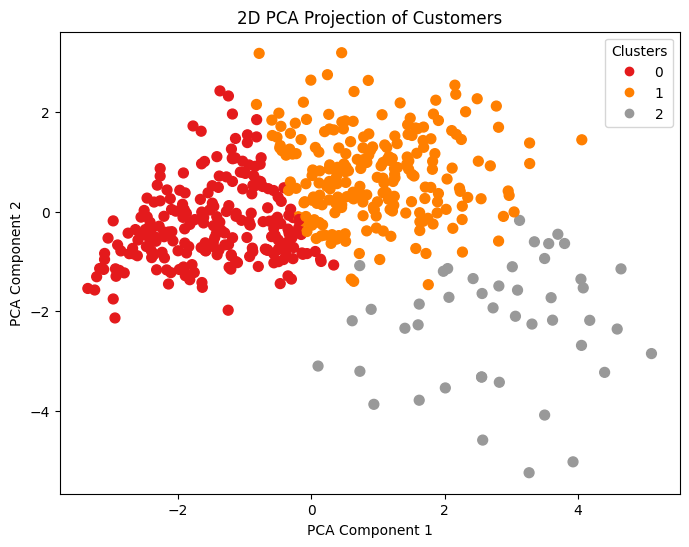

In [ ]:
#Visualize 2D PCA with KMeans cluster coloring
plt.figure(figsize=(8,6))
scatter = plt.scatter(X_pca[:,0], X_pca[:,1], c=data['KMeans_cluster'], cmap='Set1', s=50)
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.title("2D PCA Projection of Customers")
plt.legend(*scatter.legend_elements(), title="Clusters")
plt.show()

In [ ]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
#Preparing LDA
# Features (same 6 numerical features)
X = X_scaled  # already standardized
y = data['KMeans_cluster']  # cluster labels as target

In [ ]:
lda = LDA(n_components=2)
X_lda = lda.fit_transform(X, y)

In [ ]:
# Explained variance ratio
lda_explained_variance = lda.explained_variance_ratio_
print(f"LDA Explained Variance Ratio (2 components): {lda_explained_variance}")
print(f"Total Variance Captured by LDA: {lda_explained_variance.sum():.2f}")


LDA Explained Variance Ratio (2 components): [0.76308243 0.23691757]
Total Variance Captured by LDA: 1.00


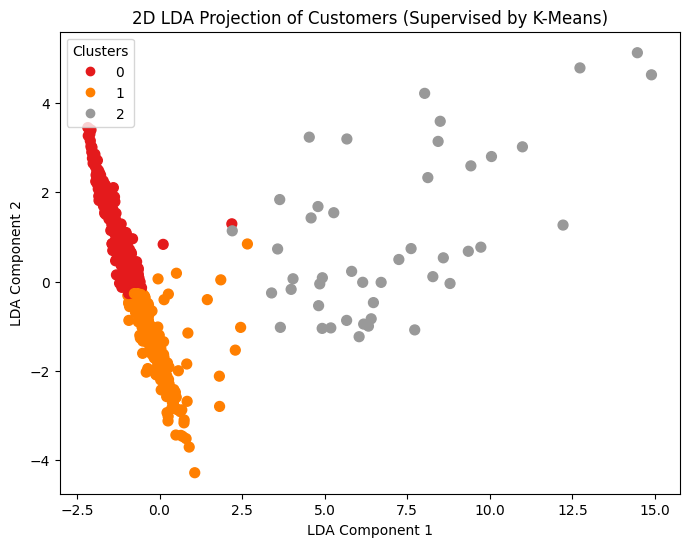

In [ ]:
# Visualize 2D LDA projection

plt.figure(figsize=(8,6))
scatter = plt.scatter(X_lda[:,0], X_lda[:,1], c=y, cmap='Set1', s=50)
plt.xlabel("LDA Component 1")
plt.ylabel("LDA Component 2")
plt.title("2D LDA Projection of Customers (Supervised by K-Means)")
plt.legend(*scatter.legend_elements(), title="Clusters")
plt.show()

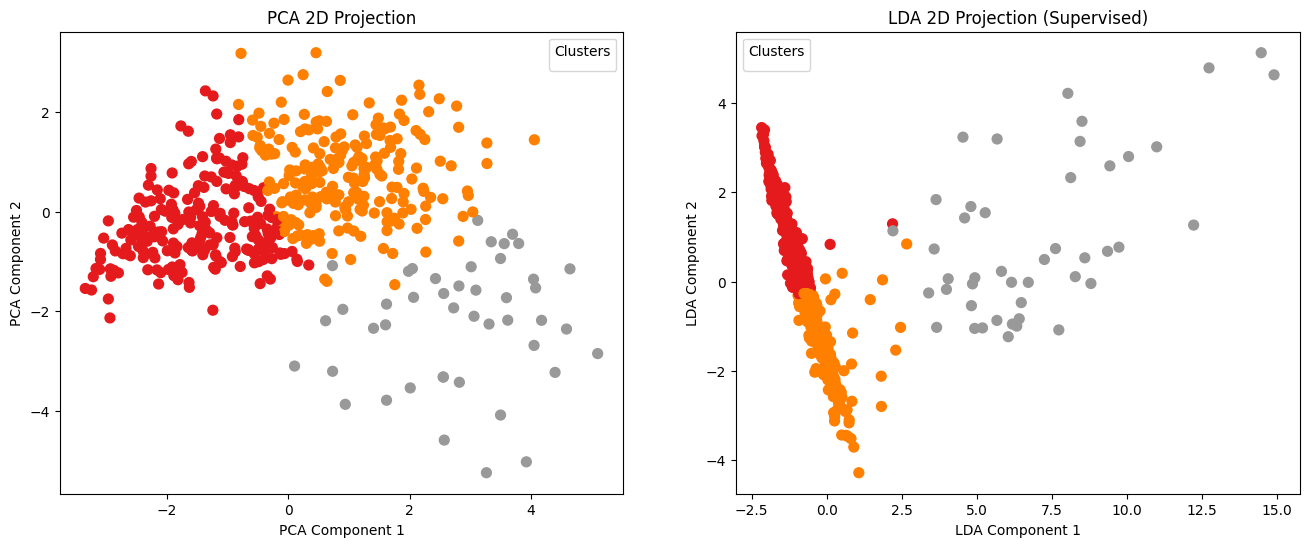

In [ ]:
#comparison between the LDA and the PCA

fig, axes = plt.subplots(1, 2, figsize=(16,6))

# PCA
axes[0].scatter(X_pca[:,0], X_pca[:,1], c=data['KMeans_cluster'], cmap='Set1', s=50)
axes[0].set_title("PCA 2D Projection")
axes[0].set_xlabel("PCA Component 1")
axes[0].set_ylabel("PCA Component 2")

# LDA
axes[1].scatter(X_lda[:,0], X_lda[:,1], c=y, cmap='Set1', s=50)
axes[1].set_title("LDA 2D Projection (Supervised)")
axes[1].set_xlabel("LDA Component 1")
axes[1].set_ylabel("LDA Component 2")

# Legends
for ax in axes:
    handles, labels = ax.get_legend_handles_labels()
    ax.legend(handles, [f"Cluster {i}" for i in range(len(set(y)))], title="Clusters")

plt.show()

Comparison Discussion

PCA:

Unsupervised, only considers variance.

Good for general dimensionality reduction, but clusters may overlap if variance alone isn’t aligned with cluster separation.

LDA:

Supervised, uses cluster labels to maximize class separation.

Provides clearer separation between clusters in 2D.

More suitable for visualizing cluster differences when labels are known.

Conclusion: For visualizing your K-Means clusters, LDA outperforms PCA because it explicitly separates clusters, while PCA only projects variance without considering cluster identity.

Customer Segments

3 segments identified using K-Means clustering:

Cluster 0 : Occasional Shoppers: Moderate income, low spending, few purchases, less website engagement.

Cluster 1 : Loyal High-Value Customers: High income, frequent purchases, high spending scores, long-term loyalty.

Cluster 2 : Active Medium-Value Customers: Moderate income, medium spending and frequency, active website users, potential to become high-value.

Cluster Insights:

Cluster 1 is the most engaged and satisfied.

Cluster 0 shows the most negative feedback and dissatisfaction.

**Customer Feedback Summary**

Positive words: "love", "great", "excellent", "helpful", "fast", "amazing", "best"

Negative words: "broken", "delayed", "buggy", "misleading", "rude", "crash"

Key themes:

Product quality and packaging

Delivery and shipping

Website/app usability

Customer service and loyalty program

Sentiment by cluster:

Cluster 1  mostly positive

Cluster 0  mostly negative

Cluster 2  mix of positive and neutral

**Dimensionality Reduction**

PCA: Unsupervised, shows overall variance, clusters overlap. Good for exploring features but not for clear separation.

LDA: Supervised, maximizes cluster separation, clearly shows differences between segments.

Takeaway: LDA is better for visualizing customer clusters.

**Business Recommendations**

Cluster 0 -Occasional Shoppers: Offer targeted discounts, improve website/app experience, encourage engagement.

Cluster 1 - Loyal Customers: Reward with exclusive offers, loyalty points, early access, and referral programs.

Cluster 2 - Active Medium-Value: Recommend products, run seasonal promotions, and incentivize loyalty to convert them into high-value.

Lowest-satisfaction cluster: Focus on delivery reliability, support responsiveness, and product quality.

Loyalty programs: Prioritize Clusters 1 and 2; use Cluster 0 strategically with low-cost incentives.

Additional data to improve analysis: Browsing behavior, CLV, product return reasons, support interaction logs, more demographic info.

Technical Recommendations
**bold text**
Clustering: K-Means is more stable and interpretable for this dataset than Hierarchical.

Visualization: LDA outperforms PCA for showing clusters clearly.

Frequency: Update this analysis quarterly to track trends, or after major campaigns.

Limitations: Keyword sentiment is basic, only numerical features used for clustering, cluster stability over time isn't guaranteed, and external market factors are ignored.